# **Распознавание рукописных цифр MNIST (Digit Recognizer)**
# **Решение с использованием HOG-признаков и логистической регрессии**
# **Данные загружаются с Google Диска**

In [ ]:
# 1. Подключение Google Диска
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Импорт библиотек
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 3. Загрузка данных с Google Диска
TRAIN_PATH = '/content/drive/MyDrive/data/digits/train2.csv'
TEST_PATH  = '/content/drive/MyDrive/data/digits/test2.csv'

train = np.loadtxt(TRAIN_PATH, delimiter=',', skiprows=1)
test  = np.loadtxt(TEST_PATH,  delimiter=',', skiprows=1)

print(f"Размер обучающей выборки: {train.shape}")
print(f"Размер тестовой выборки:  {test.shape}")

Размер обучающей выборки: (42000, 785)
Размер тестовой выборки:  (28000, 784)


In [ ]:
# 4. Разделение на метки и изображения
train_label = train[:, 0].astype(np.uint8)
train_img = train[:, 1:].reshape(-1, 28, 28)
test_img  = test.reshape(-1, 28, 28)

print(f"Изображений для обучения: {train_img.shape[0]}, теста: {test_img.shape[0]}")

Изображений для обучения: 42000, теста: 28000


In [ ]:
# 5. Извлечение HOG-признаков
def extract_hog(images):
    features = []
    for img in images:
        fd = hog(img, orientations=9, pixels_per_cell=(4, 4),
                 cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        features.append(fd)
    return np.array(features)

print("Извлечение HOG из обучающей выборки...")
X_train = extract_hog(train_img)
print("Извлечение HOG из тестовой выборки...")
X_test = extract_hog(test_img)
print(f"Размерность признаков: {X_train.shape[1]}")

Извлечение HOG из обучающей выборки...
Извлечение HOG из тестовой выборки...
Размерность признаков: 1296


In [ ]:
# 6. Разбиение на обучение и валидацию
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train, train_label, test_size=0.2, random_state=42
)

In [ ]:
# 7. Стандартизация признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_part)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

In [ ]:
# 8. Обучение модели (логистическая регрессия)
model = LogisticRegression(multi_class='multinomial', solver='lbfgs',
                           C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train_part)

LogisticRegression(max_iter=1000, multi_class='multinomial', random_state=42)

In [ ]:
# 9. Оценка на валидационной выборке
y_pred_val = model.predict(X_val_scaled)
acc = accuracy_score(y_val, y_pred_val)
print(f"Точность на валидации: {acc:.4f}")
print(classification_report(y_val, y_pred_val))

Точность на валидации: 0.9701
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       816
           1       0.98      0.99      0.99       909
           2       0.97      0.97      0.97       846
           3       0.97      0.97      0.97       937
           4       0.96      0.96      0.96       839
           5       0.97      0.96      0.97       702
           6       0.97      0.99      0.98       785
           7       0.98      0.96      0.97       893
           8       0.95      0.96      0.96       835
           9       0.96      0.97      0.96       838

    accuracy                           0.97      8400
   macro avg       0.97      0.97      0.97      8400
weighted avg       0.97      0.97      0.97      8400



In [ ]:
# 10. Предсказание на тестовой выборке
y_pred_test = model.predict(X_test_scaled)


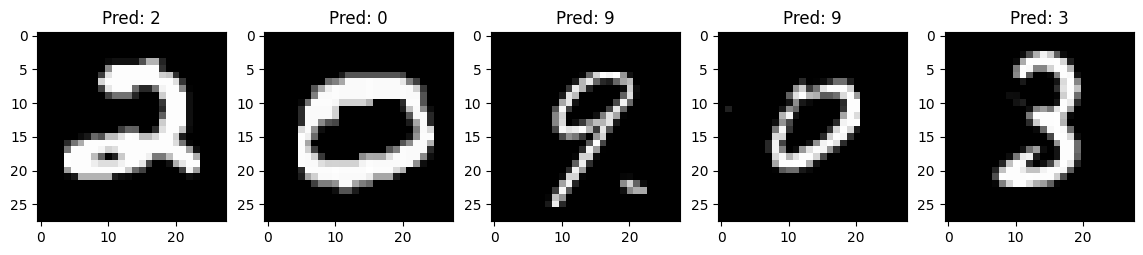

In [ ]:
# 11. Визуализация нескольких примеров (первые 5 изображений с предсказаниями)
fig = plt.figure(figsize=(20, 10))
for i in range(5):
    subplot = fig.add_subplot(1, 7, i+1)
    plt.imshow(test_img[i], cmap='gray')
    subplot.set_title(f'Pred: {y_pred_test[i]}')
plt.show()

In [ ]:
# 12. Формирование файла для отправки на Kaggle
with open('submit.csv', 'w') as f:
    f.write('ImageId,Label\n')
    for i, p in enumerate(y_pred_test, 1):
        f.write(f'{i},{p}\n')

print("Файл submit.csv успешно создан!")

Файл submit.csv успешно создан!


In [ ]:
# 13. Скачивание файла submit.csv на локальный компьютер
from google.colab import files
files.download('submit.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>